# 1 - Data sources, collection and preparation

ClimateLens forecasts tomorrow's **frost risk**, **solar energy** and **wind** for 12
German cities. This notebook walks through the data side of the project:

1. the data source and the fixed city -> station mapping,
2. a live download from the German Weather Service (DWD),
3. the stored three-year history and its validation,
4. data quality and a short exploration of the three forecast quantities,
5. the resulting preparation plan.

The notebook calls the same `climatelens` package code that runs in production on
Cloud Run (`climatelens ingest`), so what is shown here is exactly what the cloud
pipeline does.

**Run it** from the repository root after `make install` and
`pip install -r notebooks/requirements.txt`. It reads the local data folder
(`./data`); fill it once with `climatelens ingest --backfill-years 3`.

In [1]:
import os
from datetime import UTC, datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

from climatelens.config import CITIES, get_settings
from climatelens.data import (
    REQUIRED_PARAMETERS,
    VALUE_BOUNDS,
    fetch_observations,
    read_raw,
    to_wide,
    validate,
)
from climatelens.features import FEATURE_FIELDS, solar_j_cm2_to_kwh_m2

# Run from the repository root so ./data and ./models resolve as in the CLI.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIGURES = Path("notebooks/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

settings = get_settings()
print("raw data location:", settings.raw_uri)

raw data location: data\raw


## 1.1 Data source

| Item | Value |
|---|---|
| Provider | Deutscher Wetterdienst (DWD), open data server `opendata.dwd.de` |
| Datasets | daily `climate_summary` (temperature, wind, humidity, pressure, cloud, precipitation) and daily `solar` (global radiation) |
| Access | open-source Python client [`wetterdienst`](https://github.com/earthobservations/wetterdienst) 0.136, native DWD units |
| Licence | DWD open data, attribution in the dashboard and README |
| Publication | each day's values appear on the following day (observed 07:30-12:46 UTC) |

### City and station selection

The 12 most populous German cities that have a suitable station. Each city has
two stations, chosen once and then frozen in `climatelens.config.CITIES` for
reproducibility:

* a **primary station** that reports wind and pressure (many stations only record
  temperature and precipitation), and
* a **solar station**, because only 56 DWD stations measure daily radiation.

In [2]:
stations = pd.DataFrame(
    [
        {
            "city": c.name,
            "primary station": f"{c.station_name} ({c.station_id})",
            "distance km": c.station_distance_km,
            "elevation m": c.station_elevation_m,
            "solar station": f"{c.solar_station_name} ({c.solar_station_id})",
            "solar distance km": c.solar_distance_km,
        }
        for c in CITIES
    ]
)
distinct = {c.station_id for c in CITIES} | {c.solar_station_id for c in CITIES}
print(f"{len(CITIES)} cities, {len(distinct)} distinct DWD stations")
stations

12 cities, 18 distinct DWD stations


,city,primary station,distance km,elevation m,solar station,solar distance km
0,Berlin,Berlin-Tempelhof (00433),5.83,48.0,Potsdam (03987),27.89
1,Hamburg,Hamburg-Fuhlsbuettel (01975),9.14,11.0,Hamburg-Fuhlsbuettel (01975),9.14
2,Munich,Muenchen-Stadt (03379),3.77,515.0,Weihenstephan-Duernast (05404),30.78
3,Cologne,Koeln-Bonn (02667),16.04,91.0,Bochum Ruhruniversitaet (07365),60.32
4,Frankfurt am Main,Offenbach-Wetterpark (07341),7.78,119.0,Frankfurt-Main (01420),14.87
5,Stuttgart,Stuttgart Schnarrenberg (04928),5.95,314.0,Stuttgart Schnarrenberg (04928),5.95
6,Essen,Essen-Bredeney (01303),6.49,150.0,Bochum Ruhruniversitaet (07365),17.44
7,Leipzig,Leipzig-Holzhausen (02928),5.77,138.0,Leipzig-Halle (02932),14.05
8,Bremen,Bremen (00691),3.80,4.0,Bremen (00691),3.80
9,Dresden,Dresden-Klotzsche (01048),8.69,228.0,Dresden-Klotzsche (01048),8.69


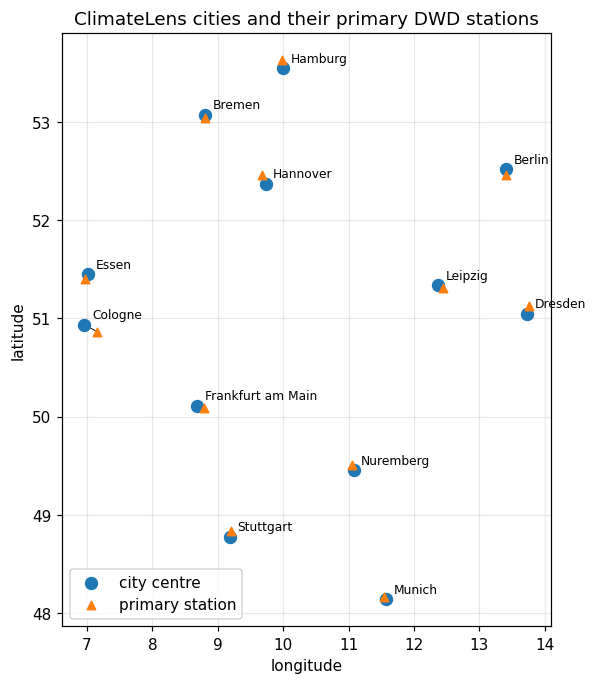

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 7))
for c in CITIES:
    lons = [c.centre_longitude, c.station_longitude]
    lats = [c.centre_latitude, c.station_latitude]
    ax.plot(lons, lats, "k-", lw=0.6)
ax.scatter(
    [c.centre_longitude for c in CITIES],
    [c.centre_latitude for c in CITIES],
    s=60,
    c="tab:blue",
    label="city centre",
    zorder=3,
)
ax.scatter(
    [c.station_longitude for c in CITIES],
    [c.station_latitude for c in CITIES],
    s=30,
    marker="^",
    c="tab:orange",
    label="primary station",
    zorder=3,
)
for c in CITIES:
    ax.annotate(
        c.name,
        (c.centre_longitude, c.centre_latitude),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
    )
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("ClimateLens cities and their primary DWD stations")
ax.set_aspect(1.5)
ax.legend(loc="lower left")
plt.show()

## 1.2 Live collection from DWD

`fetch_observations` downloads both datasets for a date range, retries with
exponential back-off, and adds the city to every row (a solar station can feed
several cities). The example below downloads the last ten days for Berlin only.
DWD delivers a **long** table: one row per station, parameter and day.

In [4]:
berlin = CITIES[0]
end = datetime.now(UTC).replace(hour=0, minute=0, second=0, microsecond=0)
start = end - timedelta(days=10)
try:
    sample = fetch_observations(
        start, end, climate_ids=[berlin.station_id], solar_ids=[berlin.solar_station_id]
    )
except Exception as exc:  # noqa: BLE001 - the notebook still works on stored data
    sample = None
    print(f"DWD is not reachable right now ({exc}); the rest uses the stored history.")

if sample is not None:
    print(f"{len(sample)} rows fetched for {start:%Y-%m-%d} .. {end:%Y-%m-%d}")
    display(sample.head(8))
    display(sample.groupby(["dataset", "parameter"]).size().rename("rows").to_frame().T)

130 rows fetched for 2026-10-08 .. 2026-10-18


,station_id,city,dataset,parameter,date,value,quality
0,00433,berlin,climate_summary,cloud_cover_total,2026-10-08,6.4,1.0
1,00433,berlin,climate_summary,cloud_cover_total,2026-10-09,6.9,1.0
2,00433,berlin,climate_summary,cloud_cover_total,2026-10-10,5.8,1.0
3,00433,berlin,climate_summary,cloud_cover_total,2026-10-11,6.5,1.0
4,00433,berlin,climate_summary,cloud_cover_total,2026-10-12,1.2,1.0
5,00433,berlin,climate_summary,cloud_cover_total,2026-10-13,5.8,1.0
6,00433,berlin,climate_summary,cloud_cover_total,2026-10-14,6.3,1.0
7,00433,berlin,climate_summary,cloud_cover_total,2026-10-15,7.6,1.0


dataset     climate_summary                                                                                               \
parameter cloud_cover_total humidity precipitation_form precipitation_height pressure_air_site pressure_vapor snow_depth   
rows                     10       10                 10                   10                10             10         10   

dataset                                                                                                                             
parameter temperature_air_max_2m temperature_air_mean_2m temperature_air_min_0_05m temperature_air_min_2m wind_gust_max wind_speed  
rows                          10                      10                        10                     10            10         10

The long table is pivoted to one row per city and day (`to_wide`) and validated
(`validate`): duplicates are dropped, physically impossible values are set to
missing and counted, and calendar gaps are reported. Recent days usually have no
radiation yet, because DWD publishes solar data weeks later than the climate data.

In [5]:
if sample is not None:
    sample_wide, sample_report = validate(to_wide(sample))
    shown = ["city", "date", *REQUIRED_PARAMETERS, "radiation_global"]
    display(sample_wide[[c for c in shown if c in sample_wide.columns]].tail(6))
    print(sample_report.as_dict())

,city,date,temperature_air_mean_2m,temperature_air_min_2m,temperature_air_max_2m,wind_speed,humidity,pressure_air_site
4,berlin,2026-10-12,9.2,3.6,14.5,3.6,78.88,1014.03
5,berlin,2026-10-13,10.0,1.2,16.8,2.4,75.00,1017.72
6,berlin,2026-10-14,12.7,6.7,16.6,4.4,80.58,1020.20
7,berlin,2026-10-15,11.0,5.1,17.0,1.6,81.96,1020.65
8,berlin,2026-10-16,11.9,4.0,19.8,1.6,81.92,1015.17
9,berlin,2026-10-17,10.7,7.6,13.1,2.8,96.21,1012.47


{'rows_in': 10, 'rows_out': 10, 'duplicate_rows_dropped': 0, 'impossible_values_nulled': {}, 'missing_parameters': {'berlin': ['radiation_global']}, 'date_gaps': {}, 'warnings': []}


### Collection plan in the cloud

| Step | When | How |
|---|---|---|
| Initial backfill | once | `climatelens ingest --backfill-years 3` (from 5 Sep 2023) |
| Daily refresh | 15:30 German time | Cloud Scheduler -> `POST /jobs/ingest` on Cloud Run |
| Catch-up | automatically | a missed run is filled in by the next one (up to 60 days) |
| Storage | per day | `gs://climatelens-iu-data/raw/date=YYYY-MM-DD/stations.parquet` |

Rewriting a day overwrites its file cleanly, so re-running an ingest never creates
duplicate rows.

## 1.3 The stored history

In [6]:
raw = read_raw(settings.raw_uri)
if raw.empty:
    raise SystemExit("No stored data - run `climatelens ingest --backfill-years 3` first.")

days = raw["date"].nunique()
print(f"{len(raw):,} rows = {raw['city'].nunique()} cities x {days:,} days")
print(f"period: {raw['date'].min():%Y-%m-%d} .. {raw['date'].max():%Y-%m-%d}")
raw.groupby("city").agg(rows=("date", "size"), first=("date", "min"), last=("date", "max")).T

13,656 rows = 12 cities x 1,138 days
period: 2023-09-05 .. 2026-10-16


city,berlin,bremen,cologne,dresden,essen,frankfurt,hamburg,hannover,leipzig,munich,nuremberg,stuttgart
rows,1138,1138,1138,1138,1138,1138,1138,1138,1138,1138,1138,1138
first,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00,2023-09-05 00:00:00
last,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00,2026-10-16 00:00:00


In [7]:
clean, report = validate(raw)
summary = report.as_dict()
print("rows in / out:          ", summary["rows_in"], "/", summary["rows_out"])
print("duplicates dropped:     ", summary["duplicate_rows_dropped"])
print("impossible values:      ", summary["impossible_values_nulled"] or "none")
print("calendar gaps per city: ", summary["date_gaps"] or "none")
print("missing parameters:     ", summary["missing_parameters"] or "none")

rows in / out:           13656 / 13656
duplicates dropped:      0
impossible values:       none
calendar gaps per city:  none
missing parameters:      none


Plausibility bounds used by `validate` (DWD native units):

In [8]:
pd.DataFrame(VALUE_BOUNDS, index=["min", "max"]).T.loc[
    [p for p in VALUE_BOUNDS if p in raw.columns]
]

,min,max
temperature_air_mean_2m,-60.0,60.0
temperature_air_min_2m,-70.0,55.0
temperature_air_max_2m,-50.0,65.0
temperature_air_min_0_05m,-75.0,60.0
wind_speed,0.0,120.0
wind_gust_max,0.0,150.0
humidity,0.0,100.0
pressure_air_site,850.0,1100.0
pressure_vapor,0.0,90.0
precipitation_height,0.0,500.0


## 1.4 Data quality

Completeness per parameter decides what can be used. Model inputs are limited to
fields that are at least 98 % complete; sparse fields such as sunshine duration or
snow depth are not used.

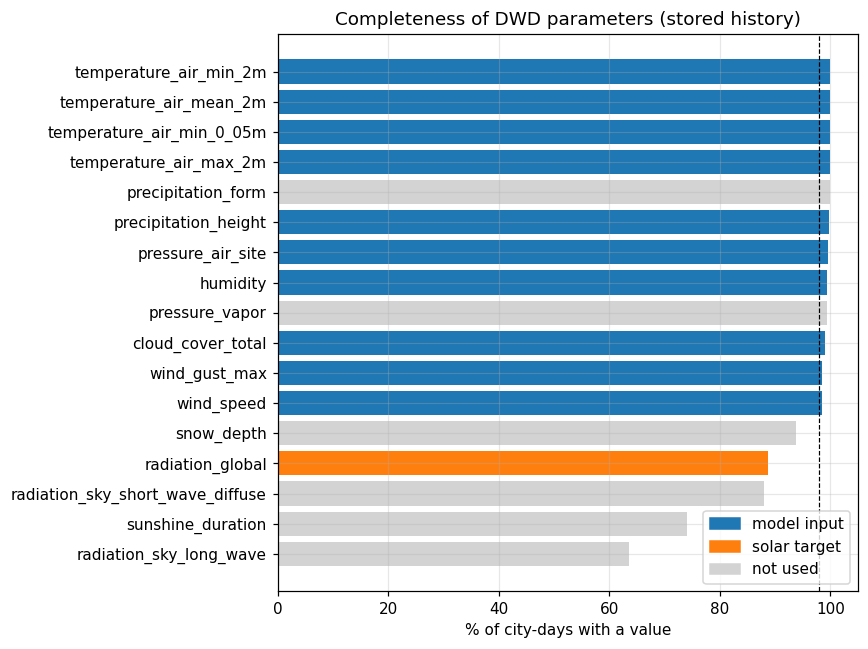

In [9]:
params = [c for c in raw.columns if c not in ("city", "station_id", "date")]
complete = (raw[params].notna().mean() * 100).sort_values()
role = [
    "model input"
    if p in FEATURE_FIELDS
    else "solar target"
    if p == "radiation_global"
    else "not used"
    for p in complete.index
]
colours = {"model input": "tab:blue", "solar target": "tab:orange", "not used": "lightgray"}

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(complete.index, complete.values, color=[colours[r] for r in role])
ax.axvline(98, color="k", ls="--", lw=0.8)
ax.set_xlabel("% of city-days with a value")
ax.set_title("Completeness of DWD parameters (stored history)")
ax.legend(handles=[Patch(color=c, label=r) for r, c in colours.items()], loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES / "data_completeness.png", bbox_inches="tight")
plt.show()

**Solar delay.** Radiation arrives weeks after the climate data (see the table).
Rows without radiation are not filled in; they are excluded only for the solar
target, while the other two targets still use them.

In [10]:
last_obs = raw.groupby("city")["date"].max()
last_solar = raw.dropna(subset=["radiation_global"]).groupby("city")["date"].max()
pd.DataFrame(
    {
        "last climate day": last_obs.dt.date,
        "last radiation day": last_solar.dt.date,
        "solar delay (days)": (last_obs - last_solar).dt.days,
    }
).T

city,berlin,bremen,cologne,dresden,essen,frankfurt,hamburg,hannover,leipzig,munich,nuremberg,stuttgart
last climate day,2026-10-16,2026-10-16,2026-10-16,2026-10-16,2026-10-16,2026-10-16,2026-10-16,2026-10-16,2026-10-16,2026-10-16,2026-10-16,2026-10-16
last radiation day,2026-07-31,2026-07-31,2026-07-31,2026-07-31,2026-07-31,2026-07-31,2026-07-31,2026-07-31,2026-07-31,2026-07-31,2026-07-31,2026-07-31
solar delay (days),77,77,77,77,77,77,77,77,77,77,77,77


## 1.5 Exploring the three forecast quantities

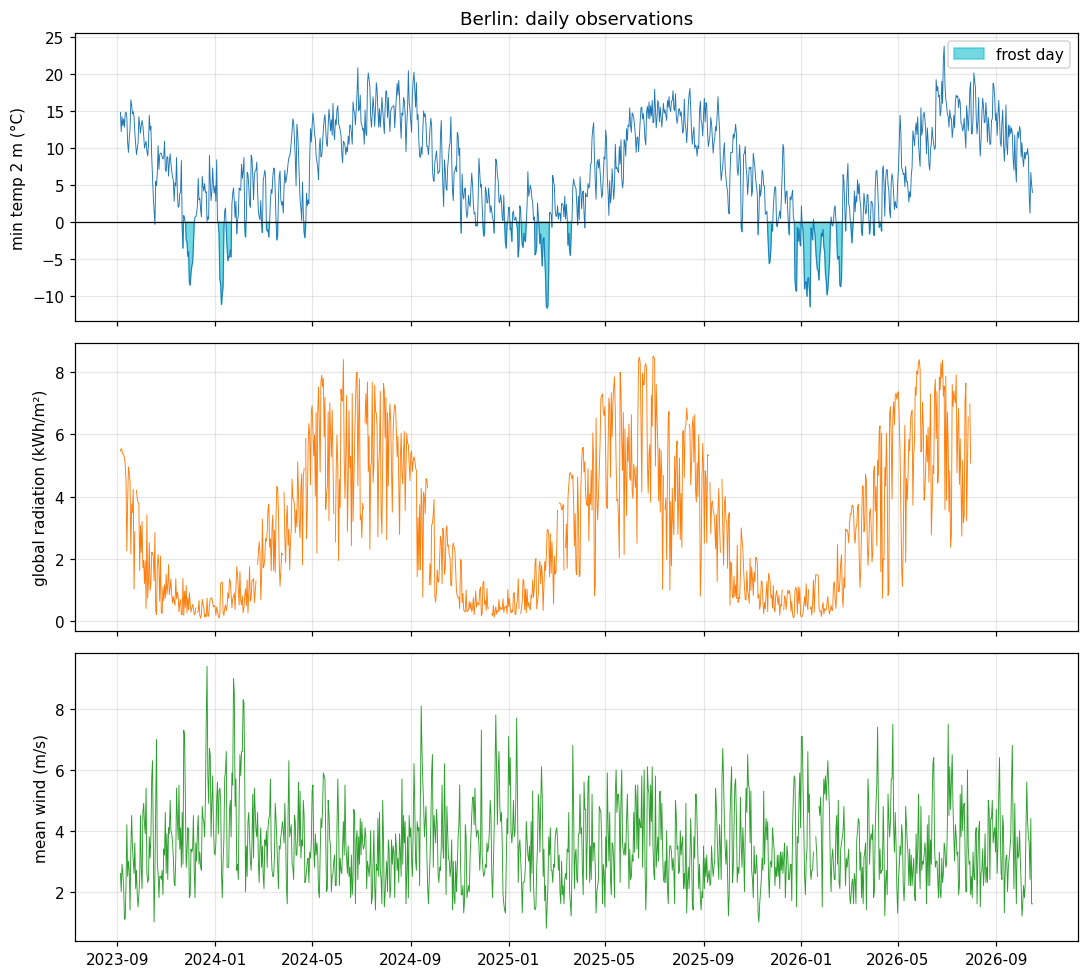

In [11]:
data = clean.copy()
data["frost"] = data["temperature_air_min_2m"] < 0
data["solar_kwh_m2"] = solar_j_cm2_to_kwh_m2(data["radiation_global"])
data["month"] = data["date"].dt.month

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
city = data[data["city"] == "berlin"].set_index("date")

axes[0].plot(city.index, city["temperature_air_min_2m"], lw=0.6, color="tab:blue")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].fill_between(
    city.index,
    city["temperature_air_min_2m"],
    0,
    where=city["frost"],
    color="tab:cyan",
    alpha=0.6,
    label="frost day",
)
axes[0].set_ylabel("min temp 2 m (°C)")
axes[0].legend(loc="upper right")
axes[0].set_title("Berlin: daily observations")

axes[1].plot(city.index, city["solar_kwh_m2"], lw=0.6, color="tab:orange")
axes[1].set_ylabel("global radiation (kWh/m²)")

axes[2].plot(city.index, city["wind_speed"], lw=0.6, color="tab:green")
axes[2].set_ylabel("mean wind (m/s)")
plt.tight_layout()
plt.savefig(FIGURES / "berlin_timeseries.png", bbox_inches="tight")
plt.show()

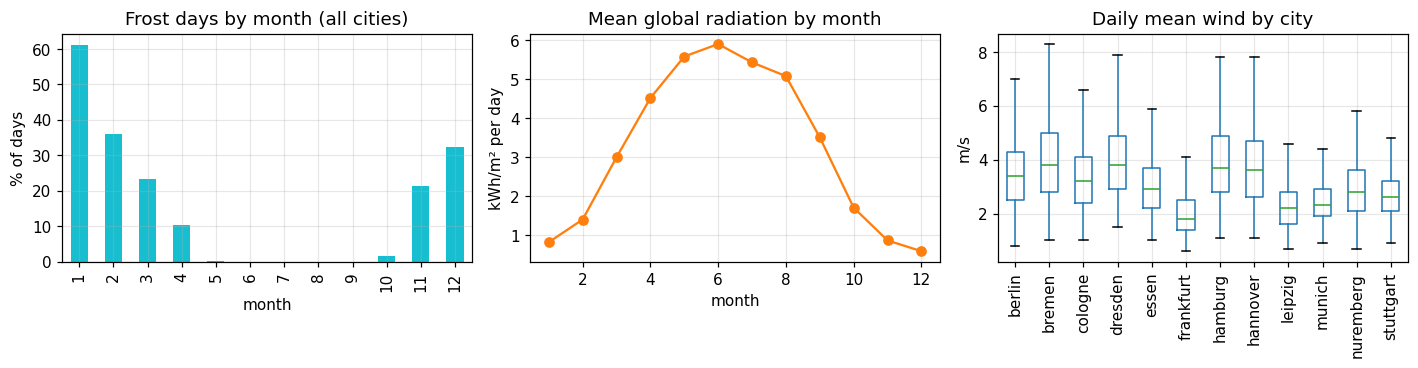

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
monthly = data.groupby("month")
(monthly["frost"].mean() * 100).plot.bar(ax=axes[0], color="tab:cyan")
axes[0].set_title("Frost days by month (all cities)")
axes[0].set_ylabel("% of days")
monthly["solar_kwh_m2"].mean().plot(ax=axes[1], marker="o", color="tab:orange")
axes[1].set_title("Mean global radiation by month")
axes[1].set_ylabel("kWh/m² per day")
data.boxplot(column="wind_speed", by="city", ax=axes[2], rot=90, showfliers=False)
axes[2].set_title("Daily mean wind by city")
axes[2].set_xlabel("")
axes[2].set_ylabel("m/s")
fig.suptitle("")
plt.tight_layout()
plt.show()

In [13]:
pd.DataFrame(
    {
        "frost days %": data.groupby("city")["frost"].mean() * 100,
        "mean radiation kWh/m²": data.groupby("city")["solar_kwh_m2"].mean(),
        "mean wind m/s": data.groupby("city")["wind_speed"].mean(),
    }
).round(2).sort_values("frost days %", ascending=False).T

city,nuremberg,dresden,leipzig,bremen,munich,berlin,hannover,hamburg,frankfurt,stuttgart,cologne,essen
frost days %,21.79,17.05,17.05,15.47,15.38,15.29,15.20,14.76,14.15,12.48,11.51,8.52
mean radiation kWh/m²,3.34,3.19,3.29,2.98,3.40,3.10,3.06,2.91,3.23,3.24,3.30,3.30
mean wind m/s,3.01,4.07,2.29,4.07,2.57,3.53,3.80,3.91,2.05,2.74,3.31,3.10


**Observations**

* Frost is strongly seasonal (none in summer, frequent in December-February) and
  occurs on roughly one day in six overall, so the frost classes are imbalanced.
* Radiation follows the annual sun cycle, with large day-to-day variation from
  cloud cover.
* Mean wind differs systematically between stations (about 2 m/s at sheltered
  Offenbach for Frankfurt, about 4 m/s at Bremen and Dresden airport), so station
  location and exposure are useful model information.

## 1.6 Preparation plan (as implemented)

| Step | Decision | Reason |
|---|---|---|
| Reshape | long -> one row per city and day | model-ready table |
| Duplicates | dropped (last value kept) | re-downloads must not double-count |
| Impossible values | set to missing and counted | bad sensor values must not train the model |
| Gaps | reported, **not imputed** | honest evaluation; LightGBM handles missing values |
| Fields | only parameters >= 98 % complete as inputs | sparse fields would add noise |
| Units | DWD native; radiation J/cm² -> kWh/m² (/360) | understandable solar unit |
| Storage | one Parquet file per day in Cloud Storage | cheap, idempotent, easy to re-read |

The next notebook turns this cleaned history into model features.